# Practical Assignment 1
# Plant Leaf Disease Classification using CNN and MobileNetV2

#**Student Name:** Harshad Santosh Dhokare
#**Student ID:** 202401110024

## Research Paper
**Identification of Plant-Leaf Diseases Using CNN and Transfer-Learning Approach**  
Electronics, 2021, 10(12), 1388.

**Paper:** https://www.mdpi.com/2079-9292/10/12/1388

## Dataset
**PlantVillage Dataset**

The TensorFlow Datasets catalog describes PlantVillage as 54,303 leaf images in 38 categories. citeturn0search0

### Experiment
We compare:

1. **Custom CNN trained from scratch**
2. **MobileNetV2 pretrained on ImageNet + transfer learning**
3. **MobileNetV2 fine-tuning**

To keep the demonstration fast and balanced, four classes are selected:

- Tomato___Early_blight
- Tomato___Late_blight
- Tomato___healthy
- Potato___Early_blight

**Important:** This notebook deliberately does NOT use `tensorflow_datasets`. The dataset is downloaded directly and read from folders, avoiding the `tfds.load` problem in the previous notebook.

# 1. Research Paper Understanding

### Problem Statement
Plant diseases can reduce agricultural productivity. Manual disease identification requires expertise and can be time-consuming. Computer vision can learn visible disease patterns from leaf images and automatically classify them.

### Why CNN?
CNNs learn spatial image features such as edges, textures, shapes and higher-level patterns.

### Why MobileNetV2?
MobileNetV2 is a lightweight pretrained CNN. It provides a useful transfer-learning baseline while keeping model complexity lower than many larger CNN architectures.

### Why compare with a custom CNN?
A custom CNN learns all features from scratch. Comparing it with MobileNetV2 shows whether pretrained features provide an advantage on the same dataset.

### Research question
**Does MobileNetV2 transfer learning and fine-tuning provide better plant-leaf disease classification than a CNN trained from scratch?**

In [ ]:
# ============================================================
# 2. IMPORT LIBRARIES
# ============================================================
import os
import random
import time
import zipfile
import shutil
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# 3. DOWNLOAD PLANTVILLAGE


We use the public PlantVillage data file referenced by the TensorFlow Datasets PlantVillage builder. The official TFDS catalog lists 54,303 images and 38 classes. citeturn0search0turn0search8


In [ ]:
# ============================================================
# 3A. DOWNLOAD DATASET DIRECTLY
# ============================================================

DATA_DIR = "/content/plantvillage_data"
ZIP_PATH = "/content/plantvillage.zip"

# Public data file used by the PlantVillage TFDS builder.
DATA_URL = (
    "https://data.mendeley.com/public-files/datasets/"
    "tywbtsjrjv/files/d5652a28-c1d8-4b76-97f3-72fb80f94efc/"
    "file_downloaded"
)

if not os.path.exists(DATA_DIR):
    os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.exists(ZIP_PATH) and not os.path.exists(
    os.path.join(DATA_DIR, "color")
):
    print("Downloading PlantVillage dataset...")
    !wget -q --show-progress "$DATA_URL" -O "$ZIP_PATH"

print("Download complete.")
print("File size (MB):", round(os.path.getsize(ZIP_PATH) / 1024**2, 2) if os.path.exists(ZIP_PATH) else "already extracted")

/content/plantvilla 100%[===================>] 827.82M  21.1MB/s    in 39s     
Download complete.
File size (MB): 827.82


In [ ]:
# ============================================================
# 3B. EXTRACT DATASET
# ============================================================

if os.path.exists(ZIP_PATH):
    print("Extracting dataset. This can take a few minutes...")
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(DATA_DIR)
    print("Extraction complete.")

# Find the directory containing class folders.
for root, dirs, files in os.walk(DATA_DIR):
    class_like = [d for d in dirs if "Tomato___healthy" in d]
    if class_like:
        DATA_ROOT = root
        break
else:
    # fallback: search recursively
    matches = glob.glob(DATA_DIR + "/**/Tomato___healthy", recursive=True)
    if not matches:
        raise FileNotFoundError(
            "PlantVillage class folders were not found after extraction."
        )
    DATA_ROOT = os.path.dirname(matches[0])

print("Dataset root:", DATA_ROOT)
print("Contains Tomato___healthy:", os.path.exists(
    os.path.join(DATA_ROOT, "Tomato___healthy")
))

Extracting dataset. This can take a few minutes...
Extraction complete.
Dataset root: /content/plantvillage_data/Plant_leave_diseases_dataset_without_augmentation
Contains Tomato___healthy: True


In [ ]:
# ============================================================
# 4. SELECT FOUR CLASSES
# ============================================================

CLASS_NAMES = [
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___healthy",
    "Potato___Early_blight"
]

MAX_PER_CLASS = 500

records = []

for label, class_name in enumerate(CLASS_NAMES):
    folder = os.path.join(DATA_ROOT, class_name)

    if not os.path.isdir(folder):
        raise FileNotFoundError(
            f"Class folder not found: {folder}"
        )

    files = []
    for ext in ("*.jpg", "*.JPG", "*.jpeg", "*.JPEG", "*.png", "*.PNG"):
        files.extend(glob.glob(os.path.join(folder, ext)))

    files = sorted(files)[:MAX_PER_CLASS]

    for path in files:
        records.append({
            "filepath": path,
            "label": label,
            "class_name": class_name
        })

dataset_df = pd.DataFrame(records)

print("Selected classes:")
print(dataset_df.groupby("class_name").size())
print("\nTotal selected images:", len(dataset_df))

Selected classes:
class_name
Potato___Early_blight    500
Tomato___Early_blight    500
Tomato___Late_blight     500
Tomato___healthy         500
dtype: int64

Total selected images: 2000


In [ ]:
# ============================================================
# 5. STRATIFIED 70/15/15 SPLIT
# ============================================================

train_df, temp_df = train_test_split(
    dataset_df,
    test_size=0.30,
    stratify=dataset_df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nClass distribution:")
display(pd.DataFrame({
    "Train": train_df["label"].value_counts().sort_index(),
    "Validation": val_df["label"].value_counts().sort_index(),
    "Test": test_df["label"].value_counts().sort_index()
}, index=CLASS_NAMES))

Training: 1400
Validation: 300
Testing: 300

Class distribution:


,Train,Validation,Test
Tomato___Early_blight,NaN,NaN,NaN
Tomato___Late_blight,NaN,NaN,NaN
Tomato___healthy,NaN,NaN,NaN
Potato___Early_blight,NaN,NaN,NaN


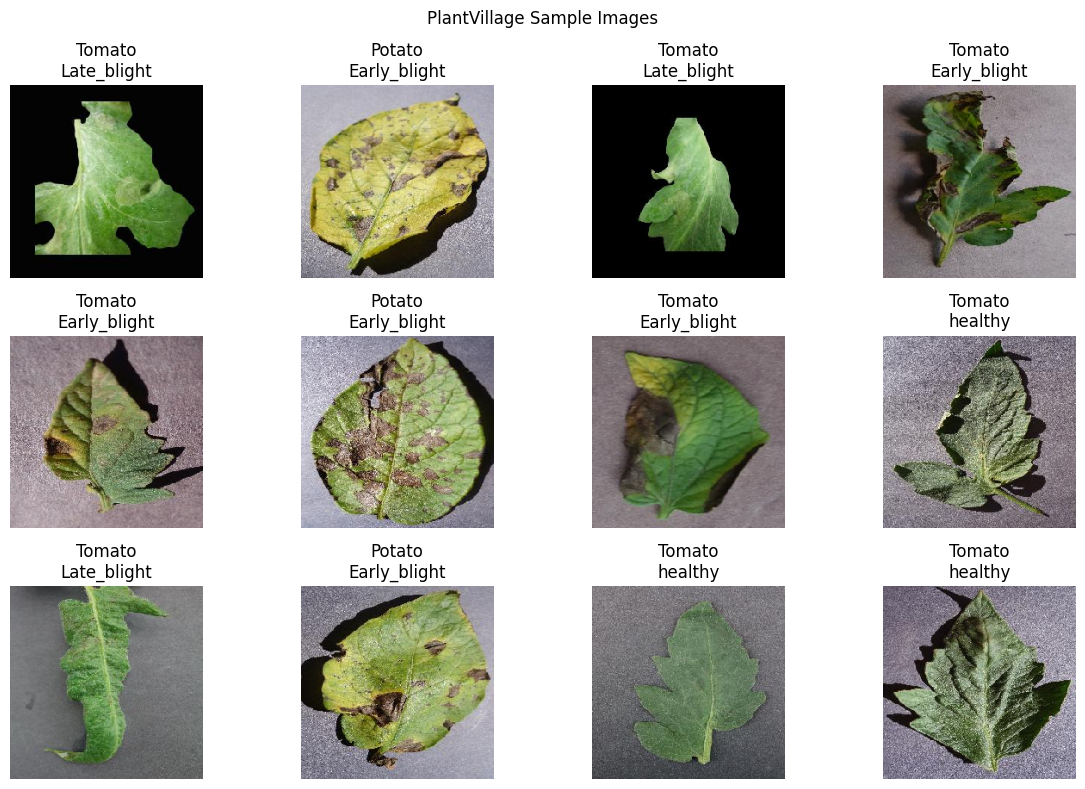

In [ ]:
# ============================================================
# 6. VISUALIZE DATA
# ============================================================

plt.figure(figsize=(12, 8))

sample_df = train_df.sample(12, random_state=SEED)

for i, (_, row) in enumerate(sample_df.iterrows()):
    image = tf.keras.utils.load_img(
        row["filepath"],
        target_size=(224, 224)
    )

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(CLASS_NAMES[row["label"]].replace("___", "\n"))
    plt.axis("off")

plt.suptitle("PlantVillage Sample Images")
plt.tight_layout()
plt.show()

# 7. PREPROCESSING

All images are resized to **224 × 224 × 3**.

Both models receive the same images and the same train/validation/test split. This makes the comparison fair.

We also apply the same augmentation strategy:

- Horizontal flip
- Small rotation
- Zoom
- Translation

In [ ]:
# ============================================================
# 8. TF.DATA INPUT PIPELINE
# ============================================================

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(CLASS_NAMES)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (
            frame["filepath"].values,
            frame["label"].values.astype("int32")
        )
    )

    if training:
        ds = ds.shuffle(
            len(frame),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: (224, 224)
Batch size: 32


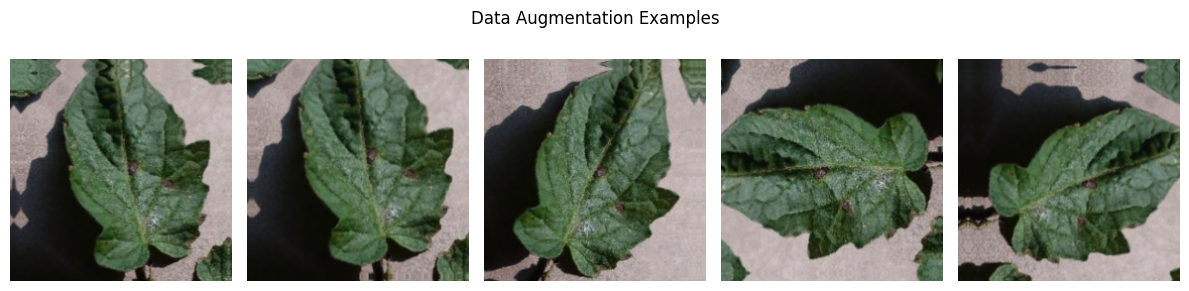

In [ ]:
# ============================================================
# 9. DATA AUGMENTATION
# ============================================================

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(0.05, 0.05)
], name="data_augmentation")

sample_path = train_df.iloc[0]["filepath"]
sample_image = tf.keras.utils.load_img(
    sample_path,
    target_size=IMG_SIZE
)
sample_array = tf.keras.utils.img_to_array(sample_image)[None, ...]

plt.figure(figsize=(12, 3))

for i in range(5):
    augmented = data_augmentation(
        sample_array,
        training=True
    )

    plt.subplot(1, 5, i + 1)
    plt.imshow(tf.cast(augmented[0], tf.uint8))
    plt.axis("off")

plt.suptitle("Data Augmentation Examples")
plt.tight_layout()
plt.show()

# Task 2 – Model 1: Custom CNN

The first model is trained completely from scratch.

### Architecture

```text
Input
 ↓
Data Augmentation
 ↓
Rescaling
 ↓
Conv2D 32
 ↓
MaxPooling
 ↓
Conv2D 64
 ↓
MaxPooling
 ↓
Conv2D 128
 ↓
MaxPooling
 ↓
Global Average Pooling
 ↓
Dense 128
 ↓
Dropout
 ↓
Softmax – 4 classes
```

In [ ]:
# ============================================================
# 10. CUSTOM CNN
# ============================================================

custom_cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    data_augmentation,
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(
        32, 3, padding="same", activation="relu",
        name="conv1"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(
        64, 3, padding="same", activation="relu",
        name="conv2"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(
        128, 3, padding="same", activation="relu",
        name="conv3"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.40),

    tf.keras.layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
], name="Custom_CNN")

custom_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

custom_cnn.summary()
print("Custom CNN parameters:", custom_cnn.count_params())

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,172 (434.27 KB)

 Trainable params: 110,724 (432.52 KB)

 Non-trainable params: 448 (1.75 KB)

Custom CNN parameters: 111172


In [ ]:
# ============================================================
# 11. TRAIN CUSTOM CNN
# ============================================================

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6
    )
]

start_time = time.time()

history_cnn = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks,
    verbose=1
)

cnn_time = time.time() - start_time

print(
    f"Custom CNN training time: "
    f"{cnn_time:.2f} seconds"
)

Epoch 1/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 13s 140ms/step - accuracy: 0.7614 - loss: 0.6345 - val_accuracy: 0.2500 - val_loss: 1.4727 - learning_rate: 0.0010
Epoch 2/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 6s 126ms/step - accuracy: 0.8550 - loss: 0.3826 - val_accuracy: 0.3067 - val_loss: 1.8978 - learning_rate: 0.0010
Epoch 3/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 10s 119ms/step - accuracy: 0.8821 - loss: 0.3186 - val_accuracy: 0.2500 - val_loss: 2.9566 - learning_rate: 0.0010
Epoch 4/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 10s 122ms/step - accuracy: 0.9064 - loss: 0.2581 - val_accuracy: 0.2667 - val_loss: 2.9367 - learning_rate: 3.0000e-04
Epoch 5/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 122ms/step - accuracy: 0.9200 - loss: 0.2291 - val_accuracy: 0.3667 - val_loss: 3.0416 - learning_rate: 3.0000e-04
Custom CNN training time: 49.42 seconds


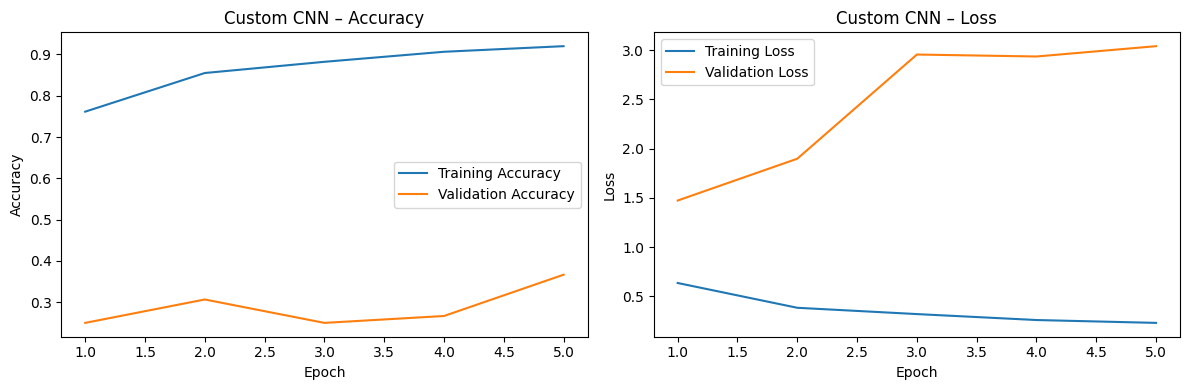

In [ ]:
# ============================================================
# 12. CNN ACCURACY AND LOSS CURVES
# ============================================================

def plot_history(history, title):
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(
        epochs,
        h["accuracy"],
        label="Training Accuracy"
    )
    plt.plot(
        epochs,
        h["val_accuracy"],
        label="Validation Accuracy"
    )
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title + " – Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(
        epochs,
        h["loss"],
        label="Training Loss"
    )
    plt.plot(
        epochs,
        h["val_loss"],
        label="Validation Loss"
    )
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title + " – Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(
    history_cnn,
    "Custom CNN"
)

# Task 2 – Model 2: MobileNetV2 Transfer Learning

MobileNetV2 is pretrained on ImageNet.

### Stage 1
The MobileNetV2 base is frozen. Only the new classification head is trained.

### Stage 2
The top 30 layers are unfrozen and fine-tuned with a small learning rate.

This allows the model to adapt useful pretrained visual features to plant-leaf disease classification.

In [ ]:
# ============================================================
# 13. MOBILE NET V2 – FEATURE EXTRACTION
# ============================================================

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = tf.keras.Input(
    shape=(224, 224, 3)
)

x = data_augmentation(inputs)

x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(
    x,
    training=False
)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.30)(x)

outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

mobilenet = tf.keras.Model(
    inputs,
    outputs,
    name="MobileNetV2"
)

mobilenet.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print(
    "Total parameters:",
    mobilenet.count_params()
)

print(
    "Trainable parameters before fine-tuning:",
    np.sum([
        np.prod(v.shape)
        for v in mobilenet.trainable_weights
    ])
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total parameters: 2263108
Trainable parameters before fine-tuning: 5124


In [ ]:
# ============================================================
# 14. TRAIN FROZEN MOBILENETV2
# ============================================================

start_time = time.time()

history_mobilenet_head = mobilenet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks,
    verbose=1
)

head_time = time.time() - start_time

print(
    f"Frozen-base training time: "
    f"{head_time:.2f} seconds"
)

Epoch 1/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 11s 122ms/step - accuracy: 0.6371 - loss: 0.8669 - val_accuracy: 0.8533 - val_loss: 0.4449 - learning_rate: 0.0010
Epoch 2/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - accuracy: 0.8443 - loss: 0.4171 - val_accuracy: 0.8900 - val_loss: 0.3308 - learning_rate: 0.0010
Epoch 3/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 74ms/step - accuracy: 0.8793 - loss: 0.3320 - val_accuracy: 0.9033 - val_loss: 0.2732 - learning_rate: 0.0010
Epoch 4/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - accuracy: 0.9014 - loss: 0.2723 - val_accuracy: 0.9033 - val_loss: 0.2481 - learning_rate: 0.0010
Epoch 5/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 80ms/step - accuracy: 0.9093 - loss: 0.2385 - val_accuracy: 0.9200 - val_loss: 0.2416 - learning_rate: 0.0010
Epoch 6/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.9229 - loss: 0.2184 - val_accuracy: 0.9267 - val_loss: 0.2142 - learning_rate: 0.0010
Epoch 7/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step - accuracy: 0.9307 - loss: 0.1965 - val_accuracy

In [ ]:
# ============================================================
# 15. FINE-TUNE MOBILENETV2
# ============================================================

base_model.trainable = True

# Freeze all except the final 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Freeze BatchNormalization layers
for layer in base_model.layers:
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False

mobilenet.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print(
    "Trainable parameters after fine-tuning:",
    np.sum([
        np.prod(v.shape)
        for v in mobilenet.trainable_weights
    ])
)

start_time = time.time()

history_mobilenet_ft = mobilenet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks,
    verbose=1
)

fine_tune_time = time.time() - start_time
mobilenet_time = head_time + fine_tune_time

print(
    f"Fine-tuning time: "
    f"{fine_tune_time:.2f} seconds"
)

print(
    f"Total MobileNetV2 time: "
    f"{mobilenet_time:.2f} seconds"
)

Trainable parameters after fine-tuning: 1515844
Epoch 1/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 12s 117ms/step - accuracy: 0.9357 - loss: 0.1867 - val_accuracy: 0.9233 - val_loss: 0.1860 - learning_rate: 1.0000e-05
Epoch 2/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 84ms/step - accuracy: 0.9364 - loss: 0.1666 - val_accuracy: 0.9400 - val_loss: 0.1628 - learning_rate: 1.0000e-05
Epoch 3/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 85ms/step - accuracy: 0.9464 - loss: 0.1540 - val_accuracy: 0.9400 - val_loss: 0.1511 - learning_rate: 1.0000e-05
Epoch 4/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 82ms/step - accuracy: 0.9529 - loss: 0.1297 - val_accuracy: 0.9500 - val_loss: 0.1384 - learning_rate: 1.0000e-05
Epoch 5/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 84ms/step - accuracy: 0.9621 - loss: 0.1186 - val_accuracy: 0.9600 - val_loss: 0.1263 - learning_rate: 1.0000e-05
Epoch 6/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step - accuracy: 0.9621 - loss: 0.0998 - val_accuracy: 0.9533 - val_loss: 0.1459 - learning_rate: 1.0000e-05
Epoch 7/8
44/44 ━━━━━━━━━━

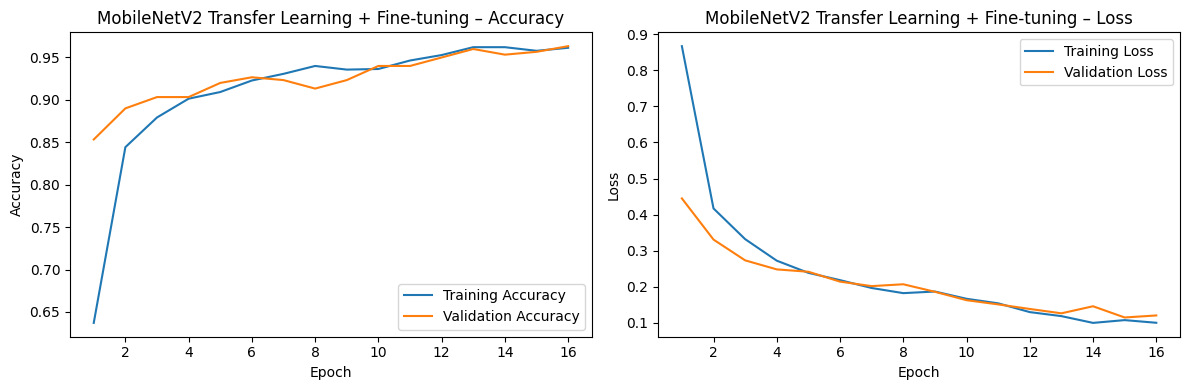

In [ ]:
# ============================================================
# 16. MOBILE NET V2 CURVES
# ============================================================

combined_history = {}

for key in history_mobilenet_head.history:
    combined_history[key] = (
        history_mobilenet_head.history[key]
        + history_mobilenet_ft.history.get(key, [])
    )

class HistoryWrapper:
    def __init__(self, history):
        self.history = history

plot_history(
    HistoryWrapper(combined_history),
    "MobileNetV2 Transfer Learning + Fine-tuning"
)

# 17. Feature Map Visualization

Feature maps show activations generated by convolutional layers.

For the custom CNN:
- early layers learn edges,
- middle layers learn textures,
- deeper layers learn more complex disease-related patterns.

Number of feature-map layers: 3
Conv Layer 1: (1, 224, 224, 32)
Conv Layer 2: (1, 112, 112, 64)
Conv Layer 3: (1, 56, 56, 128)


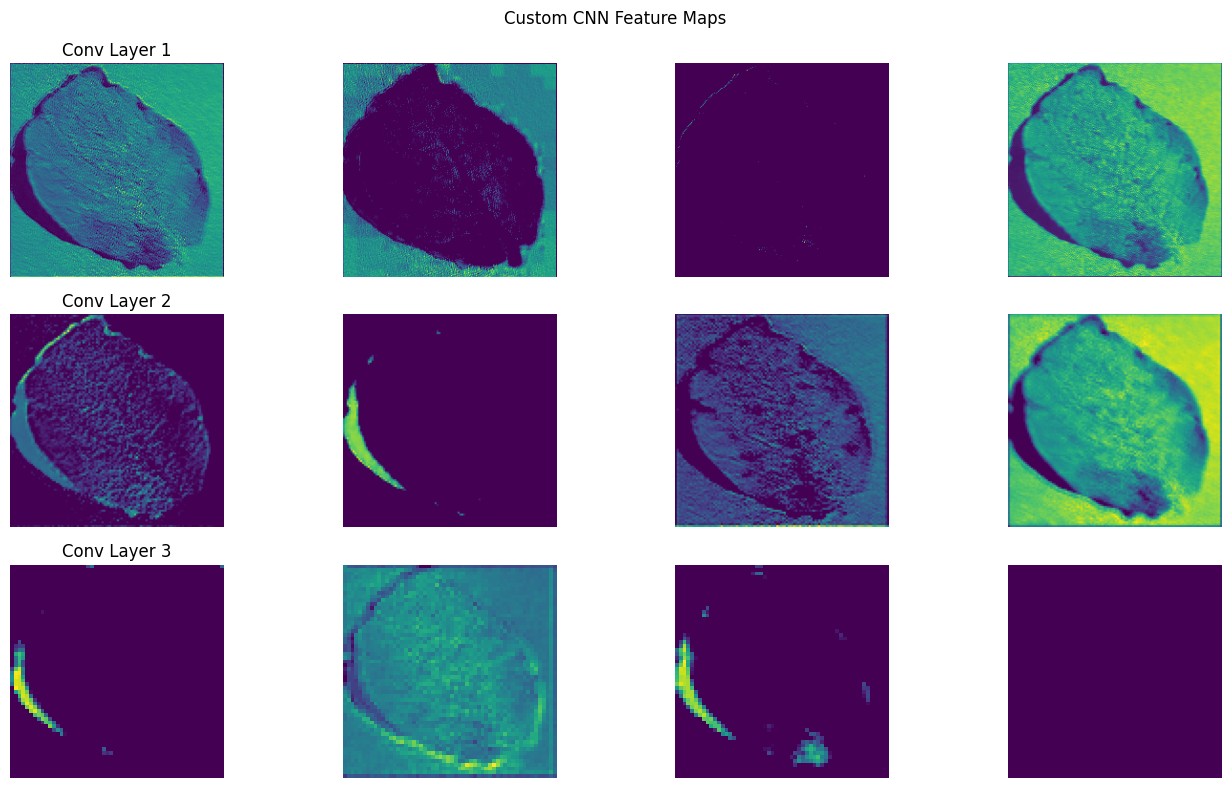

In [ ]:
# ============================================================
# 18. CUSTOM CNN FEATURE MAPS
# ============================================================

# First call the model once so Keras creates its symbolic graph
dummy_input = tf.zeros((1, 224, 224, 3))
_ = custom_cnn(dummy_input, training=False)

# Now create a feature-extraction model
feature_model = tf.keras.Model(
    inputs=custom_cnn.inputs[0],
    outputs=[
        custom_cnn.get_layer("conv1").output,
        custom_cnn.get_layer("conv2").output,
        custom_cnn.get_layer("conv3").output
    ]
)

# ------------------------------------------------------------
# Load one test image
# ------------------------------------------------------------

image = tf.keras.utils.load_img(
    test_df.iloc[0]["filepath"],
    target_size=IMG_SIZE
)

sample = tf.keras.utils.img_to_array(image)
sample = sample.astype("float32")
sample = np.expand_dims(sample, axis=0)

# ------------------------------------------------------------
# Generate feature maps
# ------------------------------------------------------------

feature_maps = feature_model.predict(
    sample,
    verbose=0
)

print("Number of feature-map layers:", len(feature_maps))

for i, fmap in enumerate(feature_maps):
    print(
        f"Conv Layer {i+1}:",
        fmap.shape
    )

# ------------------------------------------------------------
# Display feature maps
# ------------------------------------------------------------

plt.figure(figsize=(14, 8))

plot_number = 1

for layer_number, fmap in enumerate(feature_maps):

    for channel in range(4):

        plt.subplot(
            3,
            4,
            plot_number
        )

        plt.imshow(
            fmap[0, :, :, channel],
            cmap="viridis"
        )

        plt.axis("off")

        if channel == 0:
            plt.title(
                "Conv Layer " +
                str(layer_number + 1)
            )

        plot_number += 1

plt.suptitle(
    "Custom CNN Feature Maps"
)

plt.tight_layout()
plt.show()

# Task 3 – Evaluation

Both models are evaluated on the **same unseen test set**.

Metrics:

- Accuracy
- Weighted Precision
- Weighted Recall
- Weighted F1-score
- Confusion Matrix
- Training Time
- Parameter Count

Number of actual labels: 300
Number of predictions: 300

Custom CNN
Accuracy :  0.2500
Precision:  0.0625
Recall   :  0.2500
F1-score :  0.1000

Classification Report:

                       precision    recall  f1-score   support

Tomato___Early_blight       0.00      0.00      0.00        75
 Tomato___Late_blight       0.25      1.00      0.40        75
     Tomato___healthy       0.00      0.00      0.00        75
Potato___Early_blight       0.00      0.00      0.00        75

             accuracy                           0.25       300
            macro avg       0.06      0.25      0.10       300
         weighted avg       0.06      0.25      0.10       300



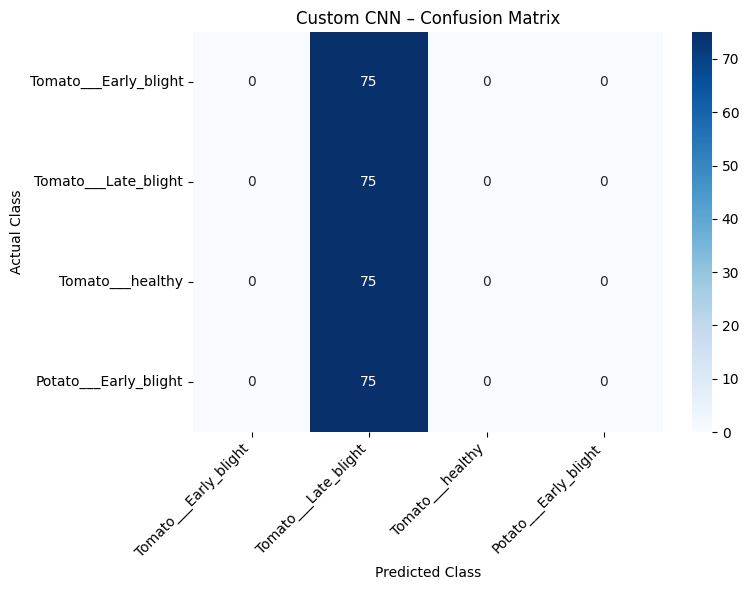

Number of actual labels: 300
Number of predictions: 300

MobileNetV2
Accuracy :  0.9400
Precision:  0.9406
Recall   :  0.9400
F1-score :  0.9398

Classification Report:

                       precision    recall  f1-score   support

Tomato___Early_blight       0.89      0.88      0.89        75
 Tomato___Late_blight       0.94      0.91      0.93        75
     Tomato___healthy       0.93      1.00      0.96        75
Potato___Early_blight       1.00      0.97      0.99        75

             accuracy                           0.94       300
            macro avg       0.94      0.94      0.94       300
         weighted avg       0.94      0.94      0.94       300



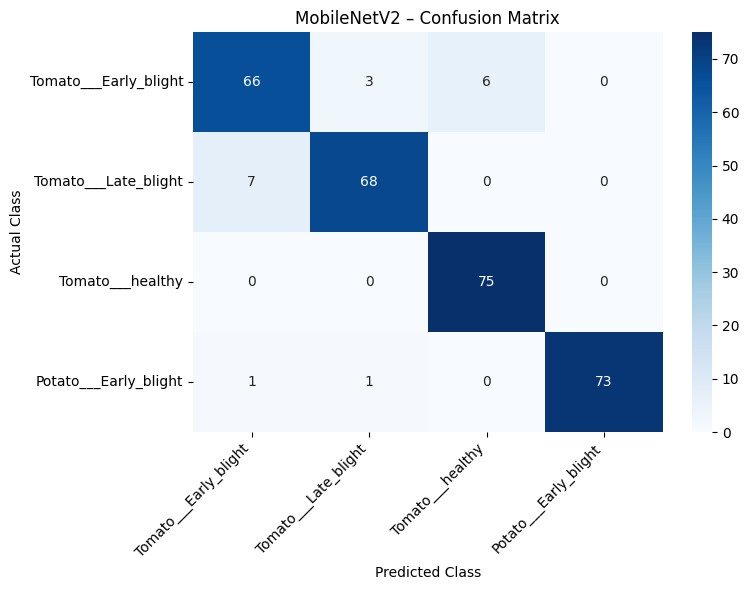

In [ ]:
# ============================================================
# 19. EVALUATION FUNCTION
# ============================================================

# IMPORTANT:
# In this version of the notebook, the true test labels
# are stored inside test_df["label"].

y_test_actual = test_df["label"].values.astype("int32")


def evaluate_model(model, dataset, true_labels, model_name):

    # Get prediction probabilities
    probabilities = model.predict(
        dataset,
        verbose=0
    )

    # Convert probabilities to class numbers
    predictions = np.argmax(
        probabilities,
        axis=1
    )

    # Safety check
    print("Number of actual labels:", len(true_labels))
    print("Number of predictions:", len(predictions))

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        true_labels,
        predictions
    )

    precision = precision_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        true_labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    # --------------------------------------------------------
    # Print results
    # --------------------------------------------------------

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print(f"Accuracy :  {accuracy:.4f}")
    print(f"Precision:  {precision:.4f}")
    print(f"Recall   :  {recall:.4f}")
    print(f"F1-score :  {f1:.4f}")

    print("\nClassification Report:\n")

    print(
        classification_report(
            true_labels,
            predictions,
            labels=list(range(NUM_CLASSES)),
            target_names=CLASS_NAMES,
            zero_division=0
        )
    )

    # --------------------------------------------------------
    # Confusion Matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        true_labels,
        predictions,
        labels=list(range(NUM_CLASSES))
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.title(
        model_name + " – Confusion Matrix"
    )

    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Return results
    # --------------------------------------------------------

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }


# ============================================================
# EVALUATE CUSTOM CNN
# ============================================================

cnn_result = evaluate_model(
    custom_cnn,
    test_ds,
    y_test_actual,
    "Custom CNN"
)


# ============================================================
# EVALUATE MOBILENETV2
# ============================================================

mobilenet_result = evaluate_model(
    mobilenet,
    test_ds,
    y_test_actual,
    "MobileNetV2"
)

,Model,Accuracy,Precision,Recall,F1-score,Training Time (seconds),Total Parameters,Final Trainable Parameters
0,Custom CNN,0.25,0.0625,0.25,0.1000,49.4230,111172,111172
1,MobileNetV2,0.94,0.9406,0.94,0.9398,74.6208,2263108,1515844


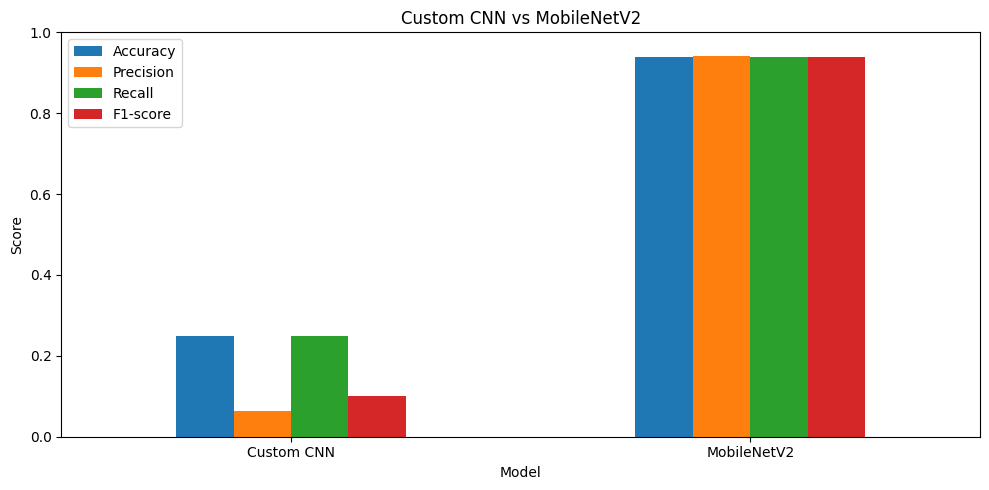

In [ ]:
# ============================================================
# 20. FINAL COMPARISON TABLE
# ============================================================

comparison = pd.DataFrame([
    cnn_result,
    mobilenet_result
])

comparison["Training Time (seconds)"] = [
    cnn_time,
    mobilenet_time
]

comparison["Total Parameters"] = [
    custom_cnn.count_params(),
    mobilenet.count_params()
]

comparison["Final Trainable Parameters"] = [
    custom_cnn.count_params(),
    np.sum([
        np.prod(v.shape)
        for v in mobilenet.trainable_weights
    ])
]

display(
    comparison.round(4)
)

# Plot metrics
comparison.set_index("Model")[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ]
].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1)
)

plt.ylabel("Score")
plt.title(
    "Custom CNN vs MobileNetV2"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

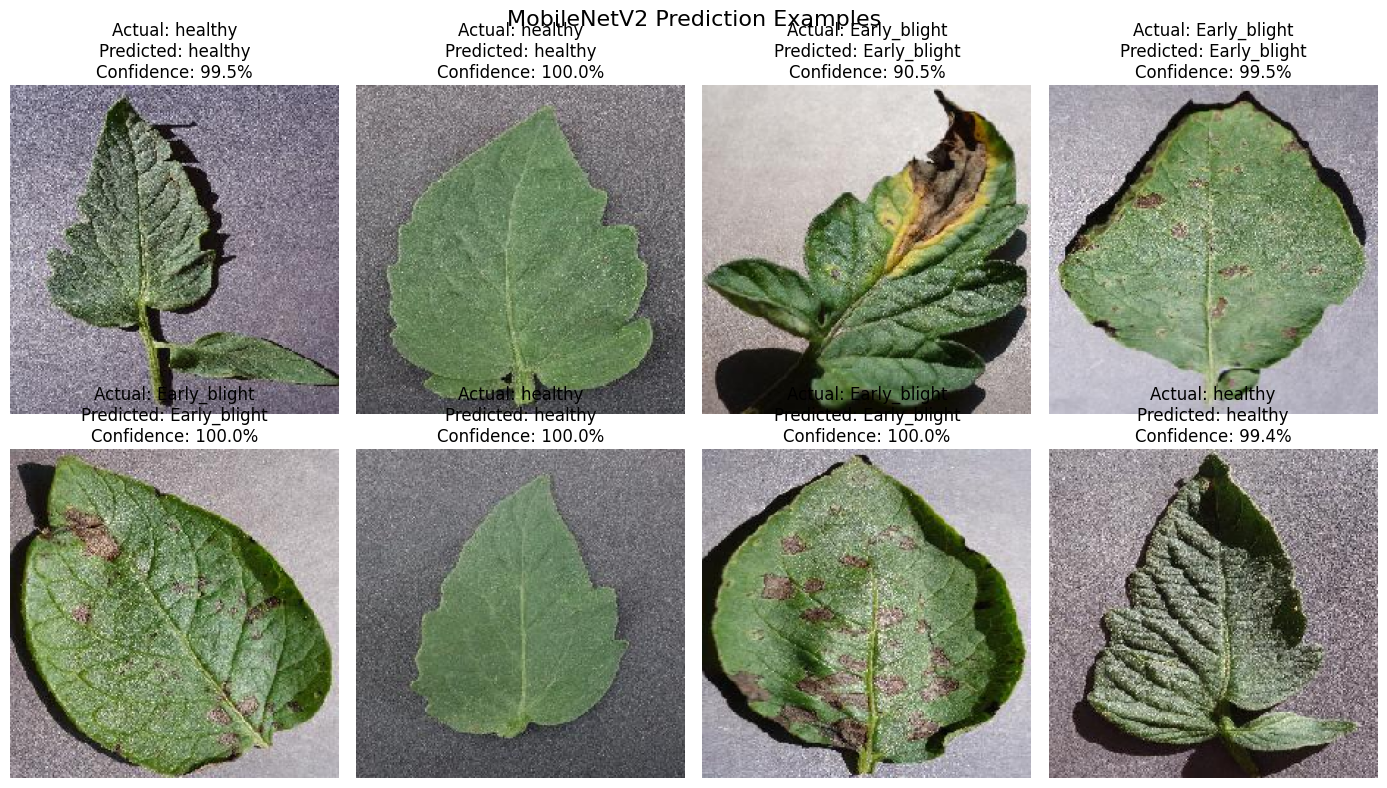

In [ ]:
# ============================================================
# 21. PREDICTION DEMONSTRATION
# ============================================================

# Select 8 random images from the test dataframe
sample_indices = np.random.choice(
    len(test_df),
    size=8,
    replace=False
)

plt.figure(figsize=(14, 8))

for plot_no, idx in enumerate(sample_indices):

    # Get image path from test dataframe
    image_path = test_df.iloc[idx]["filepath"]

    # Load image
    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE
    )

    # Convert image to NumPy array
    image_array = tf.keras.utils.img_to_array(image)

    # Add batch dimension
    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    # Get predictions from MobileNetV2
    probabilities = mobilenet.predict(
        image_array,
        verbose=0
    )[0]

    # Class with highest probability
    predicted_id = np.argmax(probabilities)

    # Actual class
    actual_id = int(
        test_df.iloc[idx]["label"]
    )

    actual = CLASS_NAMES[actual_id]

    # Predicted class
    predicted = CLASS_NAMES[predicted_id]

    # Confidence
    confidence = probabilities[predicted_id] * 100

    # --------------------------------------------------------
    # Display
    # --------------------------------------------------------

    plt.subplot(2, 4, plot_no + 1)

    plt.imshow(image)

    plt.title(
        "Actual: " +
        actual.split("___")[1] +
        "\nPredicted: " +
        predicted.split("___")[1] +
        f"\nConfidence: {confidence:.1f}%"
    )

    plt.axis("off")

plt.suptitle(
    "MobileNetV2 Prediction Examples",
    fontsize=16
)

plt.tight_layout()
plt.show()

# 22. Research Paper Comparison

The selected paper studies plant-leaf disease classification using CNN and transfer-learning approaches. Our experiment follows the same broad research methodology but is deliberately smaller and controlled for classroom demonstration.

### Paper vs Our Implementation

| Aspect | Research Paper | Our Practical |
|---|---|---|
| Application | Plant disease classification | Plant disease classification |
| Dataset | PlantVillage | PlantVillage |
| Models | Multiple pretrained CNNs | Custom CNN + MobileNetV2 |
| Classes | Research setup | 4 selected classes |
| Pretrained model | Yes | MobileNetV2 |
| Fine-tuning | Transfer-learning methodology | Yes |
| Metrics | Classification metrics | Accuracy, precision, recall, F1 |
| Confusion matrix | Used | Used |
| Curves | Used | Used |
| Comparison | Multiple models | CNN vs MobileNetV2 |

**Important:** We should not claim exact numerical reproduction because our selected classes, split, epochs, augmentation and fine-tuning configuration differ from the paper.

In [ ]:
# ============================================================
# 23. AUTOMATIC CONCLUSION
# ============================================================

best_f1 = comparison.loc[
    comparison["F1-score"].idxmax(),
    "Model"
]

best_accuracy = comparison.loc[
    comparison["Accuracy"].idxmax(),
    "Model"
]

print("=" * 60)
print("FINAL CONCLUSION")
print("=" * 60)

print(
    "Best model by F1-score:",
    best_f1
)

print(
    "Best model by accuracy:",
    best_accuracy
)

if (
    mobilenet_result["F1-score"]
    >
    cnn_result["F1-score"]
):
    print(
        "\nMobileNetV2 achieved the higher F1-score. "
        "This suggests that pretrained ImageNet features "
        "provided a useful starting representation for "
        "plant-leaf disease classification."
    )
else:
    print(
        "\nThe custom CNN achieved the higher F1-score. "
        "This demonstrates that a smaller task-specific CNN "
        "can perform strongly on the selected dataset."
    )

print(
    "\nFinal model selection should consider accuracy, "
    "precision, recall, F1-score, training time and "
    "model complexity together."
)

FINAL CONCLUSION
Best model by F1-score: MobileNetV2
Best model by accuracy: MobileNetV2

MobileNetV2 achieved the higher F1-score. This suggests that pretrained ImageNet features provided a useful starting representation for plant-leaf disease classification.

Final model selection should consider accuracy, precision, recall, F1-score, training time and model complexity together.


# 24. Advantages and Limitations

## Custom CNN

### Advantages
- Simple.
- Easy to understand.
- Architecture is fully controlled.
- Can be lightweight.

### Limitations
- Learns all features from scratch.
- Can require more training.
- More susceptible to overfitting with limited data.

## MobileNetV2

### Advantages
- Uses pretrained ImageNet features.
- Lightweight architecture.
- Usually needs less task-specific training.
- Fine-tuning adapts features to the target problem.

### Limitations
- More complex than the custom CNN.
- Pretrained features come from another domain.
- Fine-tuning requires careful learning-rate selection.

## Dataset limitation

PlantVillage images are collected under relatively controlled conditions. A model performing very well on PlantVillage may perform worse on real farm photographs with complex backgrounds, lighting and disease severity.

# 26. Conclusion

This practical implemented a complete plant-leaf disease image-classification pipeline.

A **custom CNN trained from scratch** was compared with **MobileNetV2 transfer learning and fine-tuning**.

Both models used the same four classes, preprocessing, augmentation and test set. They were evaluated using accuracy, precision, recall, F1-score, confusion matrices, training time and parameter count.

The experiment demonstrates the main advantage of transfer learning: a pretrained CNN can reuse visual features learned from a large dataset and adapt them to a new classification task.

The final model should be selected using the actual measured results rather than accuracy alone.

# 27. Declaration

I, **Harshad Dhokare**, confirm that the work submitted in this assignment is my own and has been completed following academic integrity guidelines.

**GitHub Repository Link:** https://github.com/Harsh0970/Gen-Ai/tree/main/Practical-Assign-1

**Signature:** Harshad Santosh Dhokare


# 28. Submission Checklist

- [ ] Student details
- [ ] Research paper details
- [ ] Problem statement
- [ ] Dataset description and link
- [ ] Dataset visualization
- [ ] Preprocessing
- [ ] Data augmentation
- [ ] Train/validation/test split
- [ ] Custom CNN
- [ ] CNN training
- [ ] CNN accuracy/loss curves
- [ ] MobileNetV2 transfer learning
- [ ] Fine-tuning
- [ ] Feature-map visualization
- [ ] Predictions
- [ ] Accuracy
- [ ] Precision
- [ ] Recall
- [ ] F1-score
- [ ] Confusion matrices
- [ ] Training time comparison
- [ ] Parameter comparison
- [ ] Research paper comparison
- [ ] Advantages and limitations
- [ ] Conclusion
- [ ] Viva preparation
- [ ] GitHub link